In [1]:
from pathlib import Path

from src.load_spectra import BOSZSpectra
from src.load_telluric import TelluricSpectra
from src.model import ContinuumNormalizer

import numpy as np
from matplotlib import pyplot as plt

Importing packages
End importing


In [2]:
bosz_root = Path("/home/mward19/nobackup/autodelete/bosz-spectra")
telluric_root = Path("/home/mward19/nobackup/autodelete/telluric")

In [9]:
# Same parameters as the caches the NMFs were built from, so nothing is recomputed
bosz = BOSZSpectra(
    bosz_root / Path("data"),
    300_000,
    115_000,
    D=3000,
    wave_min=3000,
    wave_max=7000,
    cache_dir=bosz_root / Path("processed-harps"),
    debug_max_F_spectra=10000,
    spectra_per_file=1000,
)
telluric = TelluricSpectra(
    telluric_root / Path("TellPCA_3000_10500_R120000.fits"),
    D=3000,
    wave_min=3000,
    wave_max=7000,
    R_out=115_000,
    n_pca=4,
    t_floor=1e-10,
    cache_dir=telluric_root / Path("processed"),
)

Parsing root directory: 100%|██████████| 628620/628620 [00:09<00:00, 66030.05file/s]


In [ ]:
wave = bosz.wave_out
# Finds nmf_F_3b9d9a3bfc.npy and nmf_G_a406df2c65.npy in the caches above instead of recomputing;
# F_kwargs are the get_F settings that file was made with (they are part of its name)
cn = ContinuumNormalizer(
    bosz,
    telluric,
    flux_errors=1e-8 * np.ones(3000),
    order_wavelengths=wave,
    F_kwargs=dict(batch=False, n_epochs=4, batch_size=1024),
)

Building sparse -log(flux) matrix (40 workers): 100%|██████████| 10/10 [00:00<00:00, 37.29chunk/s]


Sparse matrix: shape (10000, 3000), density 27.55%, 0.07 GB
Fitting NMF to 10000 x 3000 matrix, density 27.55%
violation: 1.0
violation: 4.853218638093804
violation: 2.3242320943595196
violation: 0.5421670125127384
violation: 0.40254625855605003
violation: 0.21525541476300533
violation: 0.20541399896615026
violation: 0.21398306494631175
violation: 0.1590671587995735
violation: 0.1475725225473809
violation: 0.13848624590037398
violation: 0.1211239855532465
violation: 0.10689836788765311
violation: 0.09929700507823234
violation: 0.09291623742744294
violation: 0.08380187744089312
violation: 0.08976471622351152
violation: 0.06445848511195443
violation: 0.07120637953179011
violation: 0.08392000752061306
violation: 0.06977807937476431
violation: 0.06489251936694734
violation: 0.05663546113896252
violation: 0.06451485412647857
violation: 0.04199594806055241
violation: 0.0496556492613444
violation: 0.04222237756114736
violation: 0.04186721010972014
violation: 0.052567631531947004
violation: 0.

In [ ]:
F_minibatch = cn.F.copy() # the cached MiniBatchNMF result, kept for comparison

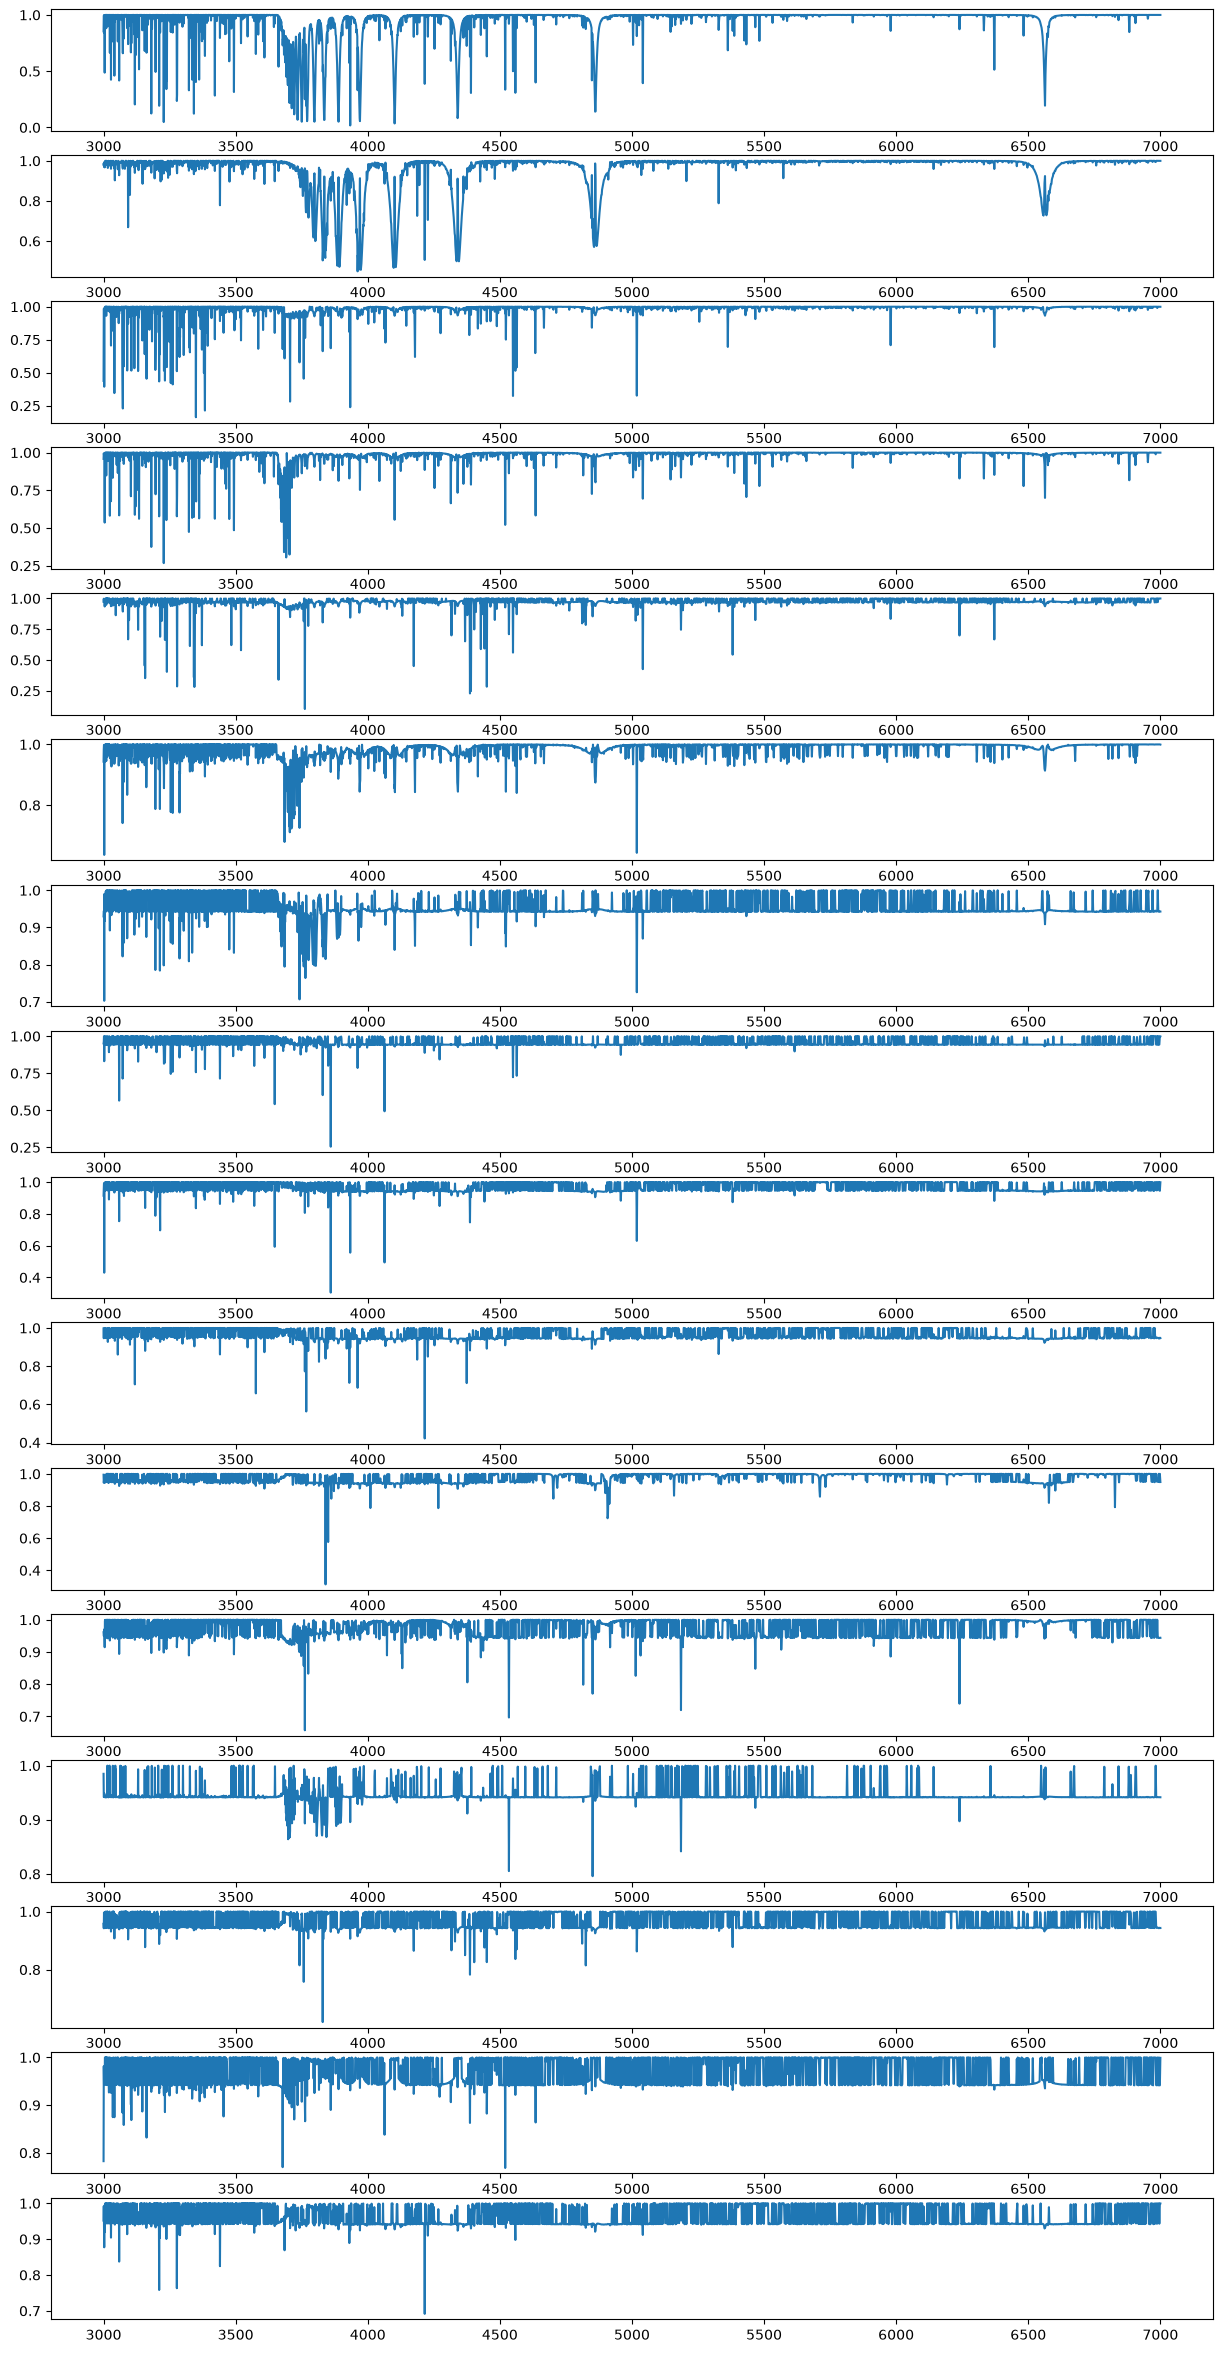

In [ ]:
_n_vecs = 16
_fig, _axes = plt.subplots(_n_vecs, figsize=(15, 30))

for _i, _ax in enumerate(_axes):
    _ax.plot(wave, np.exp(-F_minibatch[_i]))

plt.show()

In [ ]:
# MARCS atmospheres only, Teff <= 8000 K, as in the paper; then one ordinary NMF by coordinate
# descent. The paper runs 10_000 steps (~30 min); this is a short run to check the vectors.
cn.filter_spectra()
cn.fit_full(max_iter=100)
F_full = cn.F.copy()

Training on 0 of 1000 selected spectra ({'atmos': ['mp', 'ms'], 'teff_max': 8000.0})


Building sparse -log(flux) matrix (40 workers): 100%|██████████| 1/1 [00:00<00:00,  6.73chunk/s]
/home/mward19/Documents/stellar-continuum-normalization/src/model.py:199: RuntimeWarning: invalid value encountered in scalar divide
  tqdm.write(f"Fitting NMF to {X.shape[0]} x {X.shape[1]} matrix, density {X.nnz / np.prod(X.shape):.2%}")


Sparse matrix: shape (1000, 3000), density 30.02%, 0.01 GB
Fitting NMF to 0 x 3000 matrix, density nan%


ValueError: Found array with 0 sample(s) (shape=(0, 3000)) while a minimum of 1 is required by NMF.

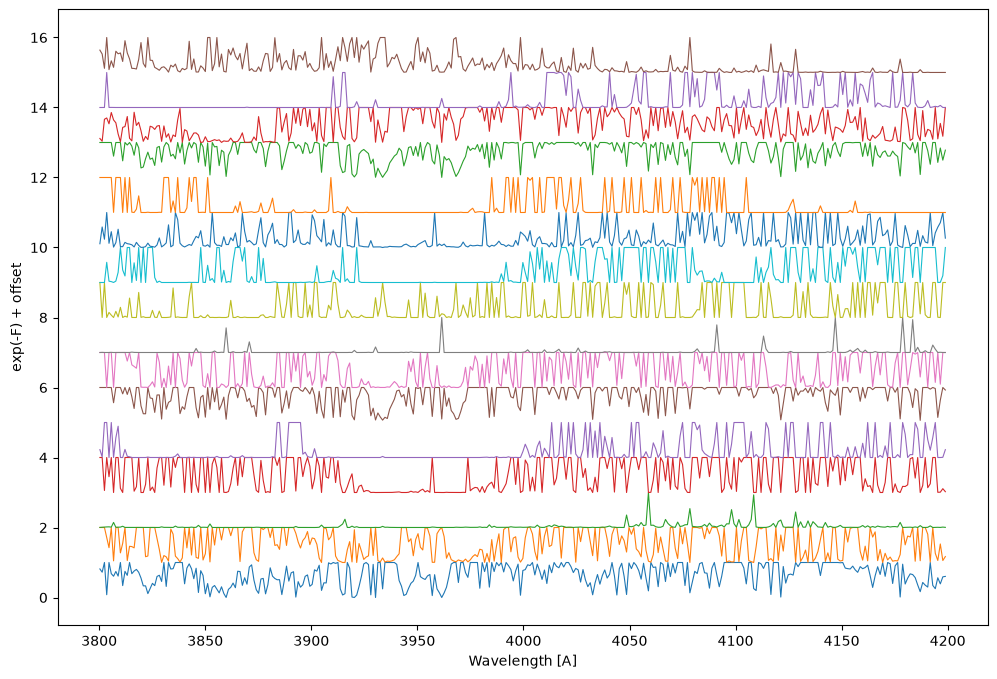

In [ ]:
# Like Figure 1 of Casey et al. (2026): basis vectors exp(-F) with offsets, 3800-4200 A
_window = (wave >= 3800) & (wave <= 4200)
_fig, _ax = plt.subplots(figsize=(12, 8))
for _i, _f in enumerate(F_full):
    _ax.plot(wave[_window], np.exp(-_f[_window]) + _i, lw=0.8)
_ax.set_xlabel("Wavelength [A]")
_ax.set_ylabel("exp(-F) + offset")
plt.show()